# ADY201m – Report 2: Data Collection & Storage
**Topic:** Product Price Analysis and Comparison between Bach Hoa Xanh (BHX) and WinMart

This notebook shows how the data goes **from the websites → raw JSON → clean CSV → matched pairs → SQL Server**.
Every number below is computed from the real files in this project; nothing is typed by hand.

Run the cells from top to bottom (Kernel → Restart & Run All).

## 1. Project objective
- Collect **real** product prices from the public websites of BHX and WinMart.
- Clean and validate the data, keeping a trace back to the raw source.
- Find products that are **truly the same** in both stores (same brand, size, pack, variant).
- Store everything in SQL Server so price history can be analysed in Report 3.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from report2 import settings, storage

pd.set_option('display.max_colwidth', 60)
PROCESSED, REPORTS, RAW = settings.PROCESSED_DIR, settings.REPORTS_DIR, settings.RAW_DIR
RUN_ID = sorted(p.name for p in RAW.glob('run_*') if (p / 'manifest.json').exists())[-1]
print('Project folder:', ROOT)
print('Run analysed  :', RUN_ID)

Project folder: C:\Users\lvqua\Projects\ADY201m_Python
Run analysed  : run_20261012_1622


## 2. Data sources
| Store | Website | Price context |
|---|---|---|
| Bach Hoa Xanh | https://www.bachhoaxanh.com | default delivery area (no address chosen): `provinceId=1027`, `storeId=2546` |
| WinMart | https://winmart.vn | online store `storeCode=1535` (`storeGroupCode=1998`) |

Prices depend on the store/area and the time. We record both for every price.

**Category scope** (`config/report2_sources.json`): 7 groups that both stores sell — milk & dairy, beverages,
instant food, seasoning, snacks & confectionery, household cleaning, personal care.

In [2]:
sources = json.loads(settings.SOURCES_FILE.read_text(encoding='utf-8'))
pd.DataFrame([{'group': g['group'], 'BHX categories': ', '.join(g['bhx']), 'WinMart categories': ', '.join(g['winmart'])}
              for g in sources['groups']])

,group,BHX categories,WinMart categories
0,milk_dairy,"sua-tuoi, sua-chua, sua-dac, sua-tu-hat, sua-trai-cay",sua-cac-loai--c08
1,beverages,"nuoc-ngot, nuoc-suoi-khoang, nuoc-tra, nuoc-tang-luc, nu...",do-uong-giai-khat--c09
2,instant_food,"mi, pho, hu-tieu, chao-an-lien, mien-kho",mi-thuc-pham-an-lien--c34
3,seasoning,"dau-an, nuoc-mam, nuoc-tuong, hat-nem, duong, tuong-ot-c...",gia-vi--c35
4,snacks_confectionery,"banh-quy, banh-xop, snack, keo-cung, keo-mem, socola, ba...",banh-keo--c07
5,household_cleaning,"nuoc-giat, nuoc-xa, nuoc-rua-chen, nuoc-lau-nha, bot-giat",hoa-pham-tay-rua--c10
6,personal_care,"kem-danh-rang, dau-goi, sua-tam, khan-giay, giay-ve-sinh","cham-soc-rang-mieng--c0147, cham-soc-toc--c0145, cham-so..."


## 3. Collection method (Python + Playwright)
1. Check `robots.txt` – category pages are allowed on both sites (copies saved in `evidence/robots/` and in each run folder).
2. Open each category page in Chromium like a normal visitor, then scroll until the list ends.
3. Save two kinds of evidence **exactly as received**:
   - `dom_cards`: the text of each product card visible on the page,
   - `responses`: the product-list JSON the page itself downloaded while rendering (we only *listen*; we never call the API ourselves).
4. Wait 5 seconds between pages, 60 s timeout, 1 retry. No login, no CAPTCHA solving, no anti-bot bypass.

How do we know a category is complete? WinMart reports `totalCount`; BHX's last page returns fewer items than the page size.

In [3]:
manifest = json.loads((RAW / RUN_ID / 'manifest.json').read_text(encoding='utf-8'))
pages = pd.DataFrame(manifest['pages'])
print('Started:', manifest['started_at'], ' Finished:', manifest['finished_at'])
print(pages['status'].value_counts().to_string())
pages[['store', 'group', 'category_slug', 'status', 'dom_cards', 'responses', 'end_reached', 'site_total_count']]

Started: 2026-10-12T16:22:03+07:00  Finished: 2026-10-12T16:43:23+07:00
status
ok    54


,store,group,category_slug,status,dom_cards,responses,end_reached,site_total_count
0,bhx,milk_dairy,sua-tuoi,ok,83,9,True,NaN
1,bhx,milk_dairy,sua-chua,ok,21,3,True,NaN
2,bhx,milk_dairy,sua-dac,ok,18,3,True,NaN
3,bhx,milk_dairy,sua-tu-hat,ok,24,3,True,NaN
4,bhx,milk_dairy,sua-trai-cay,ok,25,3,True,NaN
5,winmart,milk_dairy,sua-cac-loai--c08,ok,272,37,True,288.0
6,bhx,beverages,nuoc-ngot,ok,80,9,True,NaN
7,bhx,beverages,nuoc-suoi-khoang,ok,51,6,True,NaN
8,bhx,beverages,nuoc-tra,ok,61,7,True,NaN
9,bhx,beverages,nuoc-tang-luc,ok,48,6,True,NaN


## 4. Python libraries
| Library | Used for |
|---|---|
| `playwright` | open the web pages and read product cards / JSON |
| `pandas` | cleaning, validation, matching, CSV |
| `pyodbc` | connect to SQL Server (Windows Authentication, no password in code) |
| `re`, `unicodedata` | parse prices, sizes and Vietnamese text |
| `pytest` | automatic tests |

## 5. Raw data preview
One raw file = one category page. Here is one product from BHX and one from WinMart, as saved.

In [4]:
raw_bhx = json.loads((RAW / RUN_ID / 'bhx__sua-tuoi.json').read_text(encoding='utf-8'))
p = raw_bhx['responses'][0]['body']['data']['products'][0]
print('BHX keys:', list(p)[:25])
print({k: p[k] for k in ('productCode', 'name', 'brandName', 'unit', 'exchangeQuantity')}, p['productPrices'][0]['price'])
print('Visible card text:', raw_bhx['dom_cards'][0]['card_text'].replace(chr(10), ' | ')[:200])

BHX keys: ['id', 'name', 'fullName', 'url', 'avatar', 'unit', 'exchangeQuantity', 'provinceId', 'maxQuantityOnBill', 'sysPriceOnBill', 'promotionText', 'isShowPopup', 'isFresh', 'isPreFresh', 'label', 'productPrices', 'scenario', 'positionLabelImage', 'isCoolPreserve', 'productCode', 'brandName', 'priceInPricePerUnit', 'category', 'quantityCondition', 'productType']
{'productCode': '1053141000654', 'name': 'Thùng 48 bịch sữa dinh dưỡng Dutch Lady không đường 180ml', 'brandName': 'Dutch Lady', 'unit': 'Thùng', 'exchangeQuantity': 48} 353000
Visible card text: Socola | 48 hộp | x170ml | 345.000đ | /48 hộp 170ml | -9% | 380.000đ | 48 hộp sữa lúa mạch Lof Kun có thạch 170ml | MUA | 


In [5]:
raw_wm = json.loads((RAW / RUN_ID / 'winmart__sua-cac-loai--c08.json').read_text(encoding='utf-8'))
i = raw_wm['responses'][0]['body']['data']['items'][0]
print({k: i[k] for k in ('itemNo', 'barcode', 'name', 'brandName', 'uomName', 'price', 'salePrice')})
print('Paging info:', raw_wm['responses'][-1]['body'].get('paging'))

{'itemNo': '10232516', 'barcode': '8934614030066', 'name': 'Sữa đậu nành Fami nguyên chất hộp 1L', 'brandName': 'FAMI', 'uomName': 'Hộp', 'price': 21900.0, 'salePrice': 16500.0}
Paging info: {'totalCount': 288, 'pageNumber': 36, 'pageSize': 8, 'totalPages': 36}


## 6. Dataset structure
The raw JSON is flattened to one row per product per page (`raw_products_flat.csv`).

In [6]:
flat = pd.read_csv(PROCESSED / 'raw_products_flat.csv', dtype=str)
flat = flat[flat['run_id'] == RUN_ID]
print('Raw rows:', len(flat)); print(flat['store'].value_counts().to_string())
flat[['row_id', 'store', 'product_code', 'name', 'brand_raw', 'sale_price_raw', 'list_price_raw', 'unit_label']].head()

Raw rows: 3780
store
winmart    2266
bhx        1514


,row_id,store,product_code,name,brand_raw,sale_price_raw,list_price_raw,unit_label
0,run_20261012_1622|bhx|banh-bong-lan|r0|i0,bhx,1053087000346,Bánh bông lan sữa vị vani Delipie 216g,Delipie,36000.0,36000.0,Hộp
1,run_20261012_1622|bhx|banh-bong-lan|r0|i1,bhx,1053087000077,Gói 5 cái bánh bông lan sợi thịt gà Orion C'est Bon,Orion,20000.0,20000.0,Gói
2,run_20261012_1622|bhx|banh-bong-lan|r0|i2,bhx,1052841000501,Gói bánh Custas Bakery Castella trứng Lava 50g,Custas,15000.0,15000.0,Cái
3,run_20261012_1622|bhx|banh-bong-lan|r0|i3,bhx,1052841000320,Bánh bông lan bơ sữa Kido's Bakery Castella 20g,Kido's Bakery,5000.0,5000.0,Cái
4,run_20261012_1622|bhx|banh-bong-lan|r0|i4,bhx,1052841000319,Bánh bông lan socola Kido's Bakery Castella 20g,Kido's Bakery,5000.0,5000.0,Cái


## 7. Data cleaning
- Text: Unicode NFC, extra spaces removed; a normalised copy without accents for comparing.
- Prices: converted to integers in VND.
- Size: BHX structured spec first (e.g. *Dung tích: 180ml*), otherwise read from the name; kg→g and L→ml.
- Pack count: e.g. *Thùng 48 hộp* → 48. Unclear multipacks stay empty (**we do not guess**).
- BHX flash-sale prices (time-limited) are kept in a separate column; the regular shelf price is used for comparison.
- Missing values stay missing.

In [7]:
clean = pd.read_csv(PROCESSED / 'clean_observations.csv', dtype={'product_code': str, 'barcode': str})
clean = clean[clean['run_id'] == RUN_ID]
clean[['store', 'name_clean', 'brand', 'sale_price_vnd', 'list_price_vnd', 'size_value', 'size_unit',
       'pack_count', 'unit_price_vnd_per_kg_or_l', 'collected_at']].sample(8, random_state=1)

,store,name_clean,brand,sale_price_vnd,list_price_vnd,size_value,size_unit,pack_count,unit_price_vnd_per_kg_or_l,collected_at
2108,winmart,Nước Hoa Hồng Simple Soothing Facial Toner Giúp Làm Dịu ...,SIMPLE,159100,159100.0,200.0,ml,1.0,795500.0,2026-10-12T16:42:57+07:00
988,bhx,6 chai trà chanh Tea Plus Yuzu 455ml,Tea Plus,47000,62000.0,455.0,ml,6.0,17216.0,2026-10-12T16:24:40+07:00
3461,winmart,Sữa Glucerna Hương Lúa Mạch hộp 850g,GLUCERNA,967000,967000.0,850.0,g,1.0,1137647.0,2026-10-12T16:23:58+07:00
3055,winmart,Thùng 40 gói mì xào khô ăn liền vị sườn Goreng Rasa Iga ...,INDOMIE,6000,6000.0,80.0,g,1.0,75000.0,2026-10-12T16:28:27+07:00
161,bhx,Cháo tổ yến gold Yến Lộc Phát thịt bằm gói 50g,Yến Lộc Phát,9200,9200.0,50.0,g,NaN,NaN,2026-10-12T16:27:28+07:00
3000,winmart,Thùng 30 gói mì ăn liền khoai tây Cung Đình Micoem vị gà...,CUNG ĐÌNH,8500,8500.0,79.0,g,1.0,107595.0,2026-10-12T16:28:27+07:00
1176,bhx,Kẹo socola bơ đậu phộng Snickers gói 20g,Snickers,10000,10000.0,20.0,g,NaN,NaN,2026-10-12T16:32:58+07:00
2900,winmart,Xịt vải đam mê chai Downy 370ml,DOWNY,106600,106600.0,370.0,ml,1.0,288108.0,2026-10-12T16:37:00+07:00


## 8. Data validation summary

In [8]:
quality = json.loads((REPORTS / 'data_quality_report.json').read_text(encoding='utf-8'))
rows = quality['rows']
summary = pd.DataFrame({'raw rows': rows['raw_by_store'], 'clean rows': rows['clean_by_store'],
                        'rejected rows': rows['rejected_by_store'],
                        'distinct products': quality['distinct_products_by_store']}).T
display(summary)
print('Rejected by reason:', rows['rejected_by_reason'])
print('Visible card price vs JSON price:', quality['dom_price_check_clean'])

,winmart,bhx
raw rows,2266,1514
clean rows,2095,1412
rejected rows,171,102
distinct products,2095,1412


Rejected by reason: {'duplicate_in_run': 200, 'missing_product_code': 73}
Visible card price vs JSON price: {'bhx': {'match': 1366, 'match_flash_sale': 46}, 'winmart': {'match': 1890, 'not_visible': 201, 'match_weight_unit': 4}}


,bhx,winmart
brand,0.07,0.57
list_price_vnd,0.00,0.10
size_value,1.70,7.83
pack_count,4.46,6.21
barcode,100.00,0.00
unit_price_vnd_per_kg_or_l,6.09,13.70


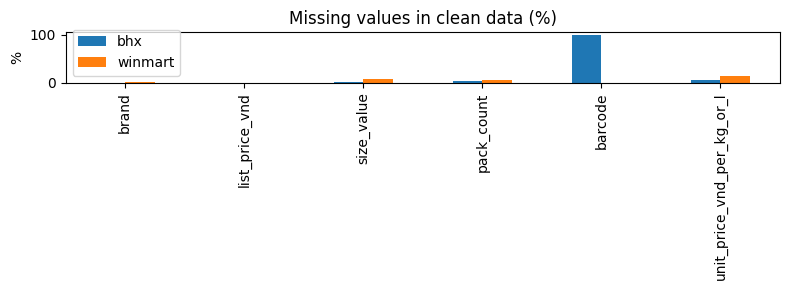

In [9]:
missing = pd.DataFrame(quality['missing_pct_clean'])
display(missing)
missing.plot.bar(figsize=(8, 3), title='Missing values in clean data (%)'); plt.ylabel('%'); plt.tight_layout(); plt.show()

## 9. Product matching (BHX ↔ WinMart)
A pair is only considered if **brand, size per unit and pack count are equal**. Then:
- flavour / sugar / product-line words must not conflict (e.g. *dâu* vs *socola* → different product),
- name similarity (word overlap) ≥ 0.5 for **MATCHED**; 0.3–0.5 or a variant word on only one side → **NEEDS_REVIEW**,
- one WinMart product can be matched to only one BHX product; ties → NEEDS_REVIEW.

Only **MATCHED** pairs go into the comparison table. NEEDS_REVIEW is kept for manual checking.

In [10]:
match_info = json.loads((REPORTS / 'matching_summary.json').read_text(encoding='utf-8'))
print('Status counts:', match_info['status_counts'])
print('Price-comparable pairs:', match_info['price_comparable_pairs'])
pd.Series(match_info['not_matched_reasons']).head(10).to_frame('NOT_MATCHED reasons')

Status counts: {'NOT_MATCHED': 1154, 'MATCHED': 139, 'NEEDS_REVIEW': 119}
Price-comparable pairs: 139


,NOT_MATCHED reasons
no_winmart_product_with_same_brand_size_and_pack,873
bhx_size_or_pack_missing,86
low_name_similarity,76
best_candidate_already_matched_to_another_bhx_product,34
"variant_conflict ['trái cây'] vs ['có thạch', 'trái cây']",3
variant_conflict ['tôm'] vs ['bò'],3
"variant_conflict ['cam', 'trái cây'] vs ['cam']",2
"variant_conflict ['chay', 'nấm'] vs ['gà']",2
"variant_conflict ['cam', 'trái cây'] vs ['dâu', 'trái cây']",2
variant_conflict ['phô mai'] vs ['socola'],1


In [11]:
matched = pd.read_csv(PROCESSED / 'matched_products.csv')
matched[['brand', 'bhx_name', 'winmart_name', 'bhx_price_vnd', 'winmart_price_vnd',
         'price_diff_vnd', 'price_diff_pct', 'name_similarity']].sample(10, random_state=2)

,brand,bhx_name,winmart_name,bhx_price_vnd,winmart_price_vnd,price_diff_vnd,price_diff_pct,name_similarity
101,ViFon,Thùng 30 gói bún riêu cua Vifon 80g,Bún riêu cua ăn liền Vifon thùng 30 gói x 80g,317000.0,345700.0,28700.0,9.05,0.600
113,Nutimilk,Lốc 4 hộp sữa tươi Nutimilk tươi sạch ít đường 180ml,Lốc 4 hộp sữa tươi tiệt trùng Nutimilk100 ít đường 180ml,36000.0,37500.0,1500.0,4.17,0.500
48,Koreno,Mì Koreno kim chi gói 100g,Mì ăn liền Koreno vị kim chi Paldo gói 100g,13000.0,12200.0,-800.0,-6.15,0.500
65,Reeva,Mì Reeva lẩu nấm chua cay gói 85g,Mì lẩu nấm chua cay Reeva gói 85g,10200.0,9300.0,-900.0,-8.82,1.000
24,Aji-ngon,Hạt nêm vị heo Aji-ngon 170g,Hạt nêm heo Aji ngon 170g,18000.0,15700.0,-2300.0,-12.78,1.000
44,Koreno,Mì trộn tương đen Koreno gói 78g,Mì Trộn Tương Đen Paldo gói 78g,8600.0,8100.0,-500.0,-5.81,0.800
2,G7,Cà phê sữa G7 3in1 800g,Cà phê hòa tan 3in1 G7 gói 800g,177000.0,204100.0,27100.0,15.31,0.500
3,G7,Cà phê đen G7 30g,Cà phê đen hòa tan G7 hộp 30g,40000.0,42500.0,2500.0,6.25,0.600
5,G7,Cà phê sữa G7 3in1 288g,Cà phê hòa tan 3in1 G7 hộp 288g,70000.0,74400.0,4400.0,6.29,0.500
89,Tea Plus,Trà ô long xanh hương chanh Tea Plus 1 lít,Trà ô long Tea Plus vị chanh 1 lít,16000.0,18700.0,2700.0,16.88,0.667


## 10. Price difference preparation
`Price Difference = WinMart price − BHX price`, `Price Difference (%) = Difference / BHX price × 100`.
Positive → WinMart is more expensive; negative → WinMart is cheaper. (Descriptive only – analysis is Report 3.)

cheaper_store
winmart       65
bhx           65
same_price     9


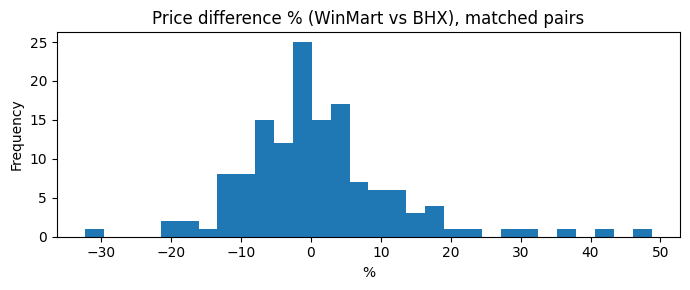

In [12]:
comp = matched[matched['price_comparable']]
print(comp['cheaper_store'].value_counts().to_string())
comp['price_diff_pct'].plot.hist(bins=30, figsize=(7, 3), title='Price difference % (WinMart vs BHX), matched pairs')
plt.xlabel('%'); plt.tight_layout(); plt.show()

## 11. Storage verification (SQL Server `ADY201m_Report2`)
The notebook only runs `SELECT` queries here.

In [13]:
conn = storage.connect()
q = lambda sql, *a: pd.read_sql(sql, conn, params=list(a) or None)
display(q('''SELECT 'Products' AS table_name, COUNT(*) AS n FROM dbo.Products
             UNION ALL SELECT 'PriceObservations', COUNT(*) FROM dbo.PriceObservations
             UNION ALL SELECT 'ProductMatches', COUNT(*) FROM dbo.ProductMatches'''))
rec = json.loads((REPORTS / f'reconciliation_{RUN_ID}.json').read_text(encoding='utf-8'))
pd.Series(rec['checks']).to_frame('passed')

,table_name,n
0,Products,3507
1,PriceObservations,3507
2,ProductMatches,258


,passed
json_rows == flat_csv_rows,True
raw_rows == clean + rejected,True
clean_csv_rows == sql_observations,True
matched_csv == sql_matched,True
needs_review_csv == sql_needs_review,True
no_duplicate_observations_in_sql,True


### Live spot-check of matched pairs (`python -m report2.verify_samples`)
12 random MATCHED pairs were opened again on both websites. WinMart: the product page price (after choosing the
same selling unit) is compared exactly. BHX: the price in the page's schema.org Product data is compared exactly.

In [14]:
ver = json.loads((REPORTS / 'sample_verification.json').read_text(encoding='utf-8'))
print(ver['summary'])
pd.DataFrame([{'store': side, 'name': p[side + '_name'][:50], 'stored': p[side]['stored_price'],
               'page now': p[side].get('page_main_price'), 'exact': p[side].get('price_match'),
               'checked_at': p[side]['checked_at']} for p in ver['pairs'] for side in ('bhx', 'winmart')])

{'sample_size': 12, 'seed': 42, 'matched_pairs_total': 139, 'bhx_title_matches': 12, 'bhx_price_match': 7, 'winmart_title_matches': 12, 'winmart_price_match': 12, 'bhx_price_found_anywhere': 12, 'winmart_price_found_anywhere': 12, 'errors': 0}


,store,name,stored,page now,exact,checked_at
0,bhx,Tương ớt Cholimex 830g,37500,35500,False,2026-10-12T17:08:37+07:00
1,winmart,Tương ớt Cholimex chai chai 830g,35500,35500,True,2026-10-12T17:08:47+07:00
2,bhx,Thùng 30 gói mì xào Hảo Hảo tôm chua ngọt 75g,129000,126000,False,2026-10-12T17:08:56+07:00
3,winmart,Thùng 30 gói mì xào khô vị tôm xào chua ngọt Hảo H,135700,135700,True,2026-10-12T17:09:06+07:00
4,bhx,Kẹo xoài muối ớt Alpenliebe 87g,18000,18000,True,2026-10-12T17:09:15+07:00
5,winmart,Kẹo Alpenliebe Hương Xoài Nhân Muối Ớt 87g,16700,16700,True,2026-10-12T17:09:24+07:00
6,bhx,Sữa dinh dưỡng Vinamilk ít đường 220ml,8400,8400,True,2026-10-12T17:09:33+07:00
7,winmart,Sữa tiệt trùng ít đường Vinamilk gói 220ml,8200,8200,True,2026-10-12T17:09:43+07:00
8,bhx,Mì xào Indomie Mi Goreng Pedas cay nồng gói 79g,6000,6000,True,2026-10-12T17:09:52+07:00
9,winmart,Thùng 40 gói mì xào khô vị cay nồng Goreng Pedas i,6000,6000,True,2026-10-12T17:10:01+07:00


## 12. SQL query examples (same as `sql/02_demo_queries.sql`)

In [15]:
q('''SELECT p.store_code, COUNT(*) AS observations, MIN(o.sale_price_vnd) AS min_price,
            MAX(o.sale_price_vnd) AS max_price, CAST(AVG(o.sale_price_vnd) AS decimal(12,0)) AS avg_price
     FROM dbo.PriceObservations o JOIN dbo.Products p ON p.product_key = o.product_key
     WHERE o.run_id = ? GROUP BY p.store_code''', RUN_ID)

,store_code,observations,min_price,max_price,avg_price
0,winmart,2095,2600.0,1226000.0,82631.0
1,bhx,1412,3600.0,1521000.0,88380.0


In [16]:
q('''SELECT run_id, product_key, COUNT(*) AS times FROM dbo.PriceObservations
     GROUP BY run_id, product_key HAVING COUNT(*) > 1''')   # expected: empty = no duplicates

,run_id,product_key,times


In [17]:
q('''SELECT TOP (10) brand, bhx_name, winmart_name, bhx_price_vnd, winmart_price_vnd, price_diff_vnd, price_diff_pct
     FROM dbo.vw_PriceComparison WHERE run_id = ? ORDER BY ABS(price_diff_pct) DESC''', RUN_ID)

,brand,bhx_name,winmart_name,bhx_price_vnd,winmart_price_vnd,price_diff_vnd,price_diff_pct
0,Twister,Nước cam ép Twister Tropicana 1 lít,Nước Cam Ép Twister 1L,16000.0,23800.0,7800.0,48.75
1,P/S,Kem đánh răng P/S muối hồng & hoa cúc 230g,Kem đánh răng P/S muối hồng và hoa cúc 230g,35000.0,50000.0,15000.0,42.86
2,Surf,Nước giặt Surf hương nước hoa túi 3.1kg,"Nước giặt hương nước hoa Surf túi 3,1kg",105000.0,143400.0,38400.0,36.57
3,Orion,Kẹo dẻo đào Orion Boom 91g,Kẹo dẻo Boom vị đào gói 91g,22000.0,14900.0,-7100.0,-32.27
4,Downy,Nước xịt vải Downy huyền bí 370ml,Xịt vải huyền bí Downy chai 370ml,82000.0,106600.0,24600.0,30.00
5,G7,Cà phê sữa G7 3in1 336g,Cà phê hòa tan 3in1 G7 hộp 336g,70000.0,90800.0,20800.0,29.71
6,Head & Shoulders,Dầu gội Head & Shoulders bạc hà 850ml,Dầu gội bạc hà Head & Shoulders 850ml,189000.0,234700.0,45700.0,24.18
7,Nam Dương,Nước tương thượng hạng Nam Dương 210ml,Nước tương thượng hạng Nam Dương chai 210ml,19900.0,24200.0,4300.0,21.61
8,Meizan,Dầu đậu nành Meizan 2 lít,Dầu đậu nành Meizan 2L,139000.0,109900.0,-29100.0,-20.94
9,Maggi,Hạt nêm Maggi nấm hương 450g,Hạt nêm cao cấp vị nấm hương Maggi gói 450g,52500.0,42200.0,-10300.0,-19.62


In [18]:
conn.close()

## 13. Limitations and next steps
- **One snapshot in time**: one run per day so far; price history needs more runs (Report 3).
- **Price context**: BHX = default area without an address; WinMart = store 1535. Other areas may have other prices.
- **No barcode on BHX**, so matching uses brand + size + pack + variant + name rules; borderline cases are NEEDS_REVIEW.
- **Category coverage**: 7 groups only; fresh food (meat, vegetables) is not comparable by brand and was left out.
- **Size/pack parsing** is rule-based; rows without a size are kept but cannot be matched.
- **Website changes**: if the sites change their pages, selectors and JSON fields must be updated.

Next (Report 3): collect several runs, review NEEDS_REVIEW pairs, analyse price differences by category and over time.